# CitizenSense - NLP-Based Public Feedback Classification and Insight System
AIRI Team PITB - AI Internship Task 4

**Data note:** the dataset is **synthetic** (generated by `scripts/01_generate_synthetic_data.py` from hand-written English / Roman Urdu phrase banks). No real citizen data is used.

Run this notebook from the `notebooks/` folder. In Google Colab: upload the project folder to Drive, `%cd` into it, then `pip install -r requirements.txt`.

In [1]:
import sys, warnings, os
warnings.filterwarnings('ignore')
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, joblib
from IPython.display import Image, display
from app.utils import clean_text, extract_keywords, analyze_feedback
pd.set_option('display.max_colwidth', 110)

## 1. Raw data and cleaning

In [2]:
raw = pd.read_csv('data/raw/feedback_raw.csv')
print(raw.shape); display(raw.sample(8, random_state=2)[['text','category','sentiment','priority','language']])

(1512, 7)


,text,category,sentiment,priority,language
1129,Power is cut for hours without any notice in our neighbourhood.,Electricity,Negative,Medium,mixed
403,Ek sawal hai: kooda uthane wali gaari kis waqt aati hai?,Sanitation,Neutral,Low,roman_urdu
1281,"Sir, What is the schedule of load shedding this week?",Electricity,Neutral,Low,english
1405,The doctor is absent during duty hours in our neighbourhood. Please look into it.,Health,Negative,Medium,english
903,"Hello, Voltage fluctuation is damaging our appliances every day.",Electricity,Negative,Medium,english
1140,"Assalam o alaikum, hamare muhalle ka filtration plant band para hai kai hafton se.",Water Supply,Negative,High,roman_urdu
859,"Janab, hospital ka staff mareezon ke sath badtameezi karta hai kai hafton se. Barae meherbani karwai karein.",Health,Negative,High,roman_urdu
173,How do I check the status of my application?,General,Neutral,Low,english


In [3]:
print(open('outputs/cleaning_report.txt').read())

Raw rows: 1512
Rows containing URLs: 32
Rows containing phone numbers: 57
Removed 7 missing/empty rows
Removed 253 exact duplicates
Removed 1 near-duplicates (cosine >= 0.985)

Final samples: 1251 | train 875 / val 188 / test 188

Category distribution:
category
Roads / Infrastructure    161
Sanitation                159
Health                    159
Electricity               157
Education                 155
General                   155
Water Supply              153
Traffic                   152

Sentiment distribution:
sentiment
Negative    908
Positive    205
Neutral     138

Priority distribution:
priority
High      368
Low       366
Medium    300
Urgent    217

Language distribution:
language
english        525
roman_urdu     475
mixed          233
multi_issue     18


In [4]:
demo = ["Call me 0300-1234567 !!  Road is BROKEN  http://x.com/a 😡", "  hamare area ki  sadak kharab hai ", "Garbge not collected plz"]
for d in demo: print(repr(d), '->', repr(clean_text(d)))

'Call me 0300-1234567 !!  Road is BROKEN  http://x.com/a 😡' -> 'call me road is broken'
'  hamare area ki  sadak kharab hai ' -> 'hamare area ki sarak kharab hai'
'Garbge not collected plz' -> 'garbage not collected please'


**Why these steps?** Lowercasing and whitespace/punctuation removal reduce vocabulary size; URLs, phone numbers, CNICs and emoji are removed for privacy and noise; duplicates are dropped so the test set is not contaminated by copies of training rows; a small normalisation map fixes frequent typos and Roman Urdu spelling variants.

## 2. Dataset overview

(1251, 12) | splits: {'train': 875, 'val': 188, 'test': 188}


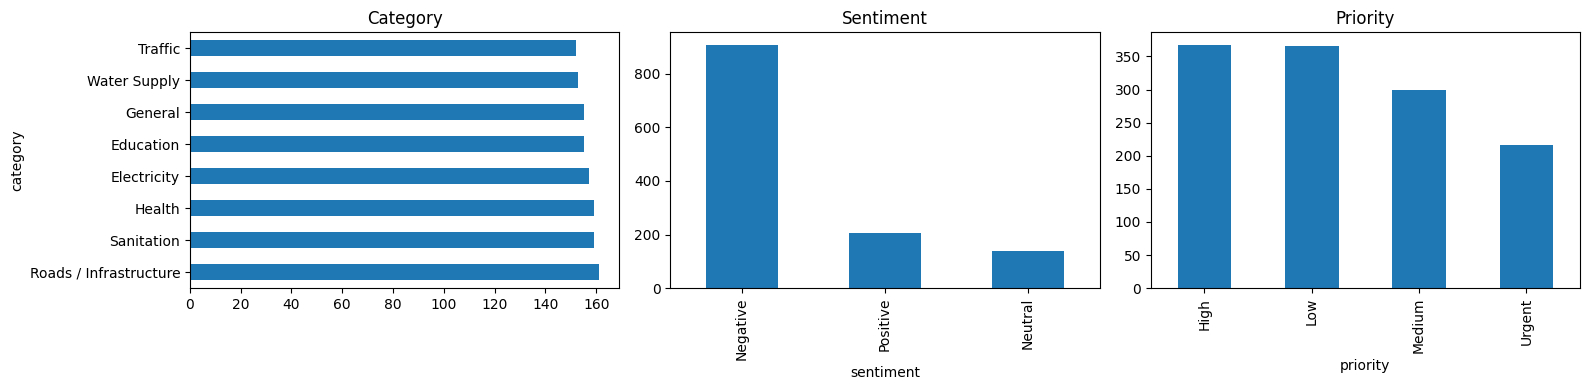

language
english        525
roman_urdu     475
mixed          233
multi_issue     18
Name: count, dtype: int64

In [5]:
df = pd.read_csv('data/processed/cleaned.csv')
print(df.shape, '| splits:', df['split'].value_counts().to_dict())
fig, ax = plt.subplots(1,3, figsize=(16,4))
df['category'].value_counts().plot.barh(ax=ax[0], title='Category'); df['sentiment'].value_counts().plot.bar(ax=ax[1], title='Sentiment'); df['priority'].value_counts().plot.bar(ax=ax[2], title='Priority')
plt.tight_layout(); plt.show()
df['language'].value_counts()

## 3. Baseline models (TF-IDF word + char n-grams)

In [6]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
train, val, test = (pd.read_csv(f'data/processed/{n}.csv') for n in ('train','val','test'))
feats = lambda: FeatureUnion([('word', TfidfVectorizer(ngram_range=(1,2), sublinear_tf=True)),
                              ('char', TfidfVectorizer(analyzer='char_wb', ngram_range=(2,5), min_df=2, sublinear_tf=True))])
lr = Pipeline([('f', feats()), ('clf', LogisticRegression(max_iter=2000, C=5, class_weight='balanced'))]).fit(train.text_clean, train.category)
print('Validation accuracy:', round(accuracy_score(val.category, lr.predict(val.text_clean)),4))
print('Test accuracy      :', round(accuracy_score(test.category, lr.predict(test.text_clean)),4))

Validation accuracy: 0.9734
Test accuracy      : 0.984


In [7]:
print(pd.read_csv('outputs/model_comparison.csv').to_string(index=False))

     task                   model  val_accuracy  val_macro_f1  test_accuracy  test_macro_f1
 category             Naive Bayes        0.9681        0.9673         0.9681         0.9685
 category     Logistic Regression        0.9734        0.9728         0.9840         0.9840
 category Linear SVM (calibrated)        0.9840        0.9840         0.9947         0.9946
 category           Random Forest        0.9840        0.9840         0.9787         0.9784
sentiment             Naive Bayes        1.0000        1.0000         0.9894         0.9855
sentiment     Logistic Regression        1.0000        1.0000         1.0000         1.0000
sentiment Linear SVM (calibrated)        1.0000        1.0000         1.0000         1.0000
sentiment           Random Forest        0.9894        0.9865         0.9894         0.9874
 priority             Naive Bayes        0.6596        0.6494         0.6755         0.6699
 priority     Logistic Regression        0.7340        0.7296         0.7872    

## 4. Evaluation of the selected category model

In [8]:
print(open('outputs/classification_report.txt').read())

===== CATEGORY (test set, n=188) =====
Accuracy: 0.9947
Macro precision: 0.9948 | Macro recall: 0.9946 | Macro F1: 0.9946

                        precision    recall  f1-score   support

             Education       1.00      1.00      1.00        24
           Electricity       0.96      1.00      0.98        23
               General       1.00      0.96      0.98        23
                Health       1.00      1.00      1.00        24
Roads / Infrastructure       1.00      1.00      1.00        24
            Sanitation       1.00      1.00      1.00        24
               Traffic       1.00      1.00      1.00        23
          Water Supply       1.00      1.00      1.00        23

              accuracy                           0.99       188
             macro avg       0.99      0.99      0.99       188
          weighted avg       0.99      0.99      0.99       188

===== SENTIMENT (test set, n=188) =====
Accuracy: 1.0000
Macro precision: 1.0000 | Macro recall: 1.0000 | 

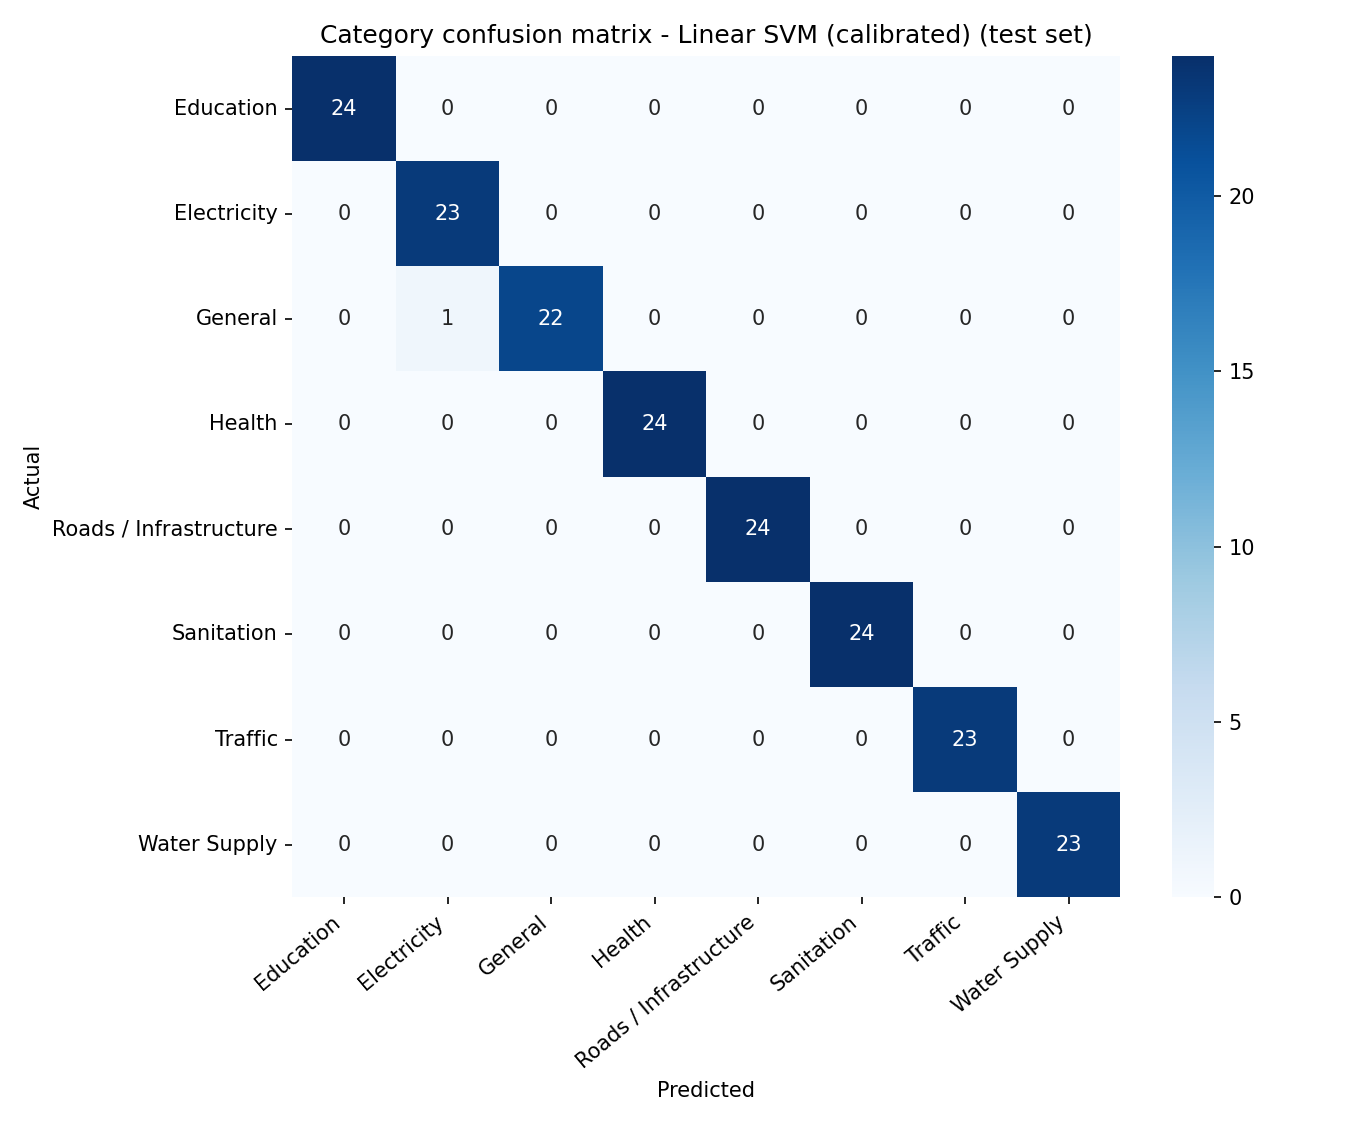

In [9]:
display(Image('outputs/confusion_matrix.png'))

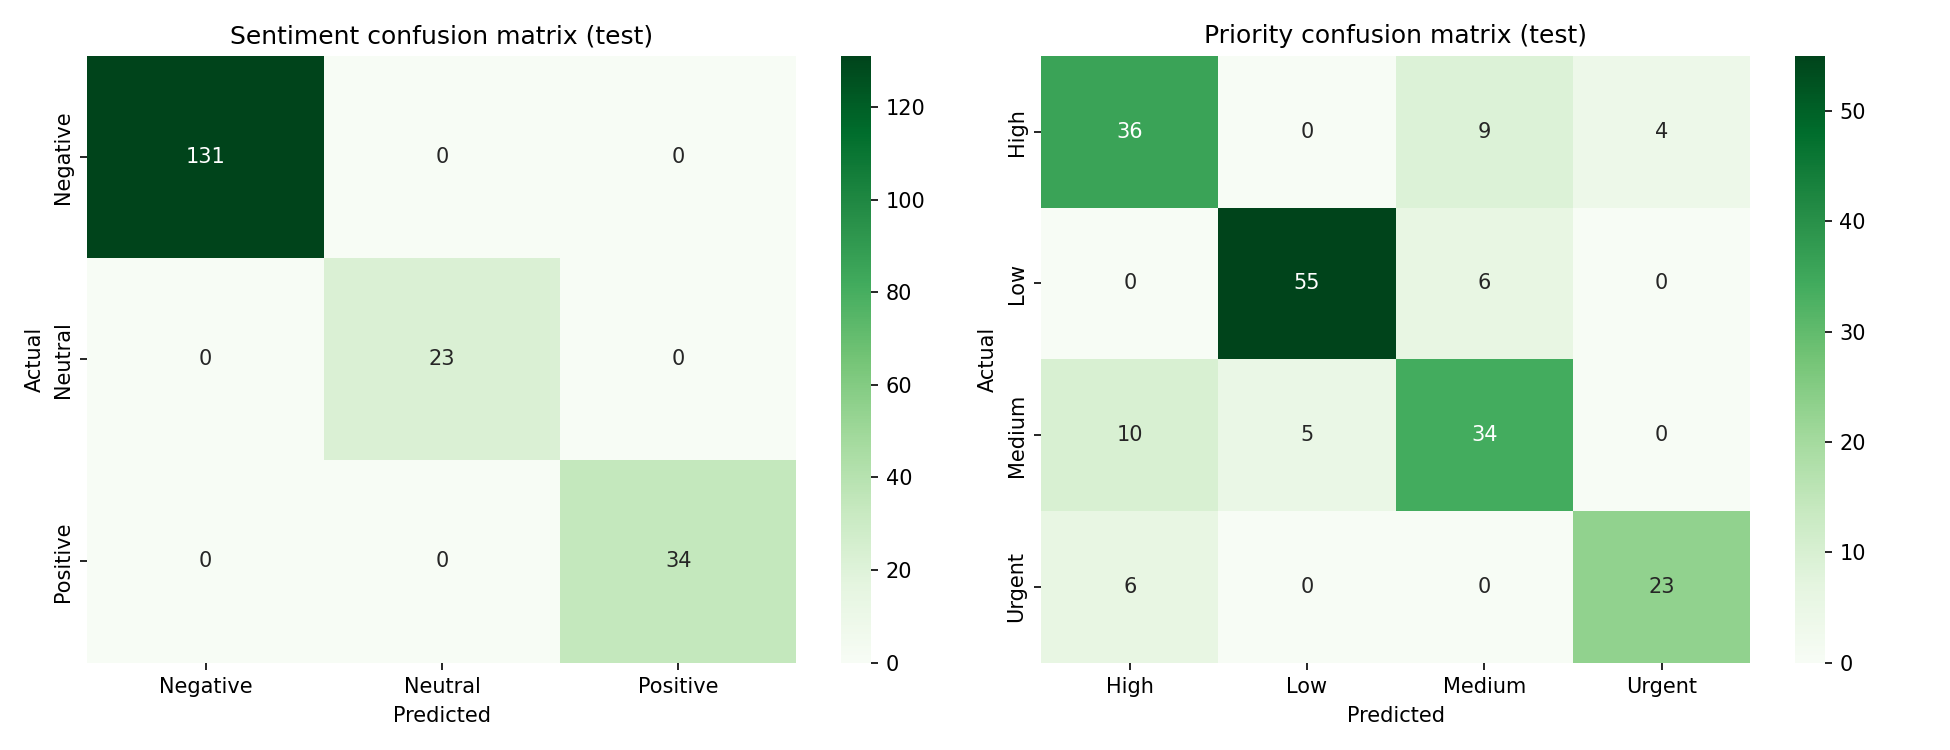

In [10]:
display(Image('outputs/confusion_matrix_sentiment_priority.png'))

### Interpretation (write your own version from your final numbers)
1. **Best / worst class:** read the per-class F1 above.
2. **Confusions:** Traffic vs Roads, Sanitation vs Roads/Water, and Health vs General share vocabulary (road, water, hospital).
3. **Why accuracy alone misleads:** sentiment is ~73% Negative, so a model that always says "Negative" gets ~73% accuracy but 0 recall on Positive/Neutral. Macro-F1 averages per-class F1, so every class counts equally.
4. **More data:** more varied, hand-written examples (esp. Roman Urdu, short texts, multi-issue messages) is the biggest lever - see the challenge-set gap below.

## 5. Honest check: hand-written challenge set

In [11]:
print(open('outputs/challenge_report.txt').read())

Challenge set size: 49

=== CATEGORY === accuracy 0.592 | macro-F1 0.551
                        precision    recall  f1-score   support

             Education       0.86      1.00      0.92         6
           Electricity       0.62      0.83      0.71         6
               General       0.50      0.67      0.57         9
                Health       0.57      0.67      0.62         6
Roads / Infrastructure       0.67      0.33      0.44         6
            Sanitation       0.44      0.80      0.57         5
               Traffic       1.00      0.17      0.29         6
          Water Supply       0.50      0.20      0.29         5

              accuracy                           0.59        49
             macro avg       0.65      0.58      0.55        49
          weighted avg       0.64      0.59      0.56        49


=== SENTIMENT === accuracy 0.898 | macro-F1 0.731

=== PRIORITY === accuracy 0.429 | macro-F1 0.385


The template test split is **optimistic** (train/test share phrasing). The hand-written challenge set is the more realistic estimate of generalisation.

## 6. Keyword extraction, summary and insight card

In [12]:
import json
for t in ["The road in our area has been broken for months and rainwater collects every day. Please fix it urgently.",
          "hamare area ki road bohat kharab hai aur pani jama hota hai",
          "There is no water supply in our area for three days."]:
    print(json.dumps(analyze_feedback(t), indent=1, ensure_ascii=False)[:900]); print('='*70)

{
 "category": "Roads / Infrastructure",
 "sentiment": "Negative",
 "priority": "High",
 "keywords": [
  "rainwater collects",
  "broken",
  "road",
  "fix"
 ],
 "suggested_department": "Municipal / Infrastructure (Roads & Works)",
 "suggested_action": "Inspect and repair the damaged road or structure",
 "summary": "Citizen reports a road or infrastructure problem involving rainwater collects, broken, road (for months) and requests urgent action.",
 "confidence": {
  "category": 0.931,
  "sentiment": 0.991,
  "priority": 0.748
 },
 "category_probabilities": {
  "Roads / Infrastructure": 0.931,
  "General": 0.03,
  "Sanitation": 0.012,
  "Water Supply": 0.009,
  "Traffic": 0.005,
  "Education": 0.005,
  "Health": 0.005,
  "Electricity": 0.004
 },
 "needs_human_review": false,
 "cleaned_text": "the road in our area has been broken for months and rainwater collects every day please fix it u
{
 "category": "Roads / Infrastructure",
 "sentiment": "Negative",
 "priority": "High",
 "keywords"

{
 "category": "Water Supply",
 "sentiment": "Negative",
 "priority": "High",
 "keywords": [
  "water supply",
  "three",
  "days"
 ],
 "suggested_department": "Water & Sanitation Agency (WASA)",
 "suggested_action": "Inspect supply line, fix leakage and restore clean water",
 "summary": "Citizen reports a water supply problem involving water supply, three, days (for three days) and requests action.",
 "confidence": {
  "category": 0.959,
  "sentiment": 0.979,
  "priority": 0.578
 },
 "category_probabilities": {
  "Water Supply": 0.959,
  "Sanitation": 0.009,
  "Health": 0.009,
  "General": 0.008,
  "Education": 0.006,
  "Electricity": 0.004,
  "Roads / Infrastructure": 0.002,
  "Traffic": 0.002
 },
 "needs_human_review": false,
 "cleaned_text": "there is no water supply in our area for three days"
}


## 7. Hugging Face transformers
Requires internet + `transformers`, `sentence-transformers`. Cells are wrapped in try/except so the notebook still runs offline; **run them in Colab to get your transformer results** and paste the numbers into your report.

In [13]:
try:
    from app.hf_models import hf_zero_shot, hf_sentiment, hf_summarize
    sample = test.sample(60, random_state=0)
    zs = [hf_zero_shot(t)[0] for t in sample.text]
    print('Zero-shot accuracy (60 test rows):', round((np.array(zs)==sample.category.values).mean(),3))
    print('Baseline accuracy on same rows   :', round((lr.predict(sample.text_clean)==sample.category.values).mean(),3))
    print('HF sentiment:', hf_sentiment('The hospital staff was helpful but the waiting time was too long.'))
    print('HF summary  :', hf_summarize('The road in our area has been broken for months. ' * 8))
except Exception as e:
    print('Transformer step skipped (needs internet/transformers):', type(e).__name__, str(e)[:120])

Transformer step skipped (needs internet/transformers): ModuleNotFoundError No module named 'transformers'


In [14]:
try:
    from app.hf_models import train_embedding_classifier, embed
    clf = train_embedding_classifier(train.text_clean, train.category)
    ch = pd.read_csv('data/raw/challenge_set.csv')
    print('Embedding+LogReg challenge accuracy:', round((clf.predict(embed(ch.text))==ch.category.values).mean(),3))
    print('TF-IDF baseline challenge accuracy :', round((lr.predict(ch.text.apply(clean_text))==ch.category.values).mean(),3))
except Exception as e:
    print('Embedding step skipped:', type(e).__name__, str(e)[:120])

Embedding step skipped: ModuleNotFoundError No module named 'sentence_transformers'


## 8. Error analysis

In [15]:
ea = pd.read_csv('outputs/error_analysis.csv'); print(len(ea), 'rows'); ea

40 rows


,text_sample,actual_category,predicted_category,confidence,error_type,possible_reason
0,The park is dirty and the street lights are off,General,Electricity,0.810,Wrong category,Shared vocabulary between categories / mixed-language wording
1,"Janab, hamare muhalle mein koi dustbin nahi hai.",Sanitation,Sanitation,0.461,Correct but low confidence,Shared vocabulary between categories / mixed-language wording
2,hamare muhalle mein koi dustbin nahi hai. Please look into it.,Sanitation,Sanitation,0.482,Correct but low confidence,Shared vocabulary between categories / mixed-language wording
3,School has no water supply and the toilets are dirty,Education,Education,0.497,Correct but low confidence,Multi-issue text mentions Education + Water
4,school ki road par traffic jam rehta hai,Traffic,Traffic,0.592,Correct but low confidence,Multi-issue text mentions Education + Roads + Traffic
5,"toot-phoot road par barish ka pani jama ho jata hai for a week. This is an emergency, act immediately!",Roads / Infrastructure,Roads / Infrastructure,0.638,Correct but low confidence,Multi-issue text mentions Roads + Water
6,I want to report that overloaded rickshaws and buses are a danger to the public in our locality for a week...,Traffic,Traffic,0.642,Correct but low confidence,Shared vocabulary between categories / mixed-language wording
7,There is a dead animal on the road and nobody removes it near the main market.,Sanitation,Sanitation,0.647,Correct but low confidence,Shared vocabulary between categories / mixed-language wording
8,Illegal construction is going on in the residential area.,General,General,0.651,Correct but low confidence,Shared vocabulary between categories / mixed-language wording
9,"Sir, Shops have encroached on the footpath in our locality.",General,General,0.697,Correct but low confidence,Shared vocabulary between categories / mixed-language wording


### Suggested improvements
1. Add 200+ hand-written, varied samples (`data/raw/manual_*.csv`) - especially short, Roman Urdu and multi-issue texts.
2. Fine-tune a multilingual transformer (e.g. `xlm-roberta-base`) instead of only TF-IDF.
3. Multi-label classification for messages that mention several issues.
4. Human review for predictions below the confidence threshold (already flagged in the app).

## 9. Sample predictions

In [16]:
pd.read_csv('outputs/sample_predictions.csv').head(20)

,text,actual_category,predicted_category,confidence,actual_sentiment,predicted_sentiment,actual_priority,predicted_priority,keywords,category_correct
0,"Sparks come out of the electric pole every time it rains in Block C. This is an emergency, act immediately!",Electricity,Electricity,0.932,Negative,Negative,Urgent,Urgent,"electric pole, sparks, out, rains",True
1,barish mein school ki chat tapakti hai for months. Kindly take action. Contact: 0321 7654321,Education,Education,0.940,Negative,Negative,Urgent,Urgent,"barish, chat, tapakti, contact",True
2,Shikayat: khara ganda pani machar paida kar raha hai.,Sanitation,Sanitation,0.942,Negative,Negative,High,High,"machar paida, pani machar, ganda pani, khara",True
3,"Janab, bhari trucks ko din mein sheher mein dakhil hone diya jata hai do din se.",Traffic,Traffic,0.933,Negative,Negative,Medium,Medium,"bhari, sheher, dakhil, diya",True
4,road khod kar chor di gayi aur dobara nahi banayi for a week. Kindly take action.,Roads / Infrastructure,Roads / Infrastructure,0.942,Negative,Negative,High,Medium,"road khod, chor, dobara, banayi",True
5,Free books were delivered on time this year. Hum bohat khush hain. Shukriya.,Education,Education,0.949,Positive,Positive,Low,Low,"free books, delivered, year, khush",True
6,"Please tell me, How do I check the status of my application?",General,General,0.956,Neutral,Neutral,Low,Low,"check, application, tell, how",True
7,gutter ka pani sarak par beh raha hai.,Sanitation,Sanitation,0.973,Negative,Negative,High,Urgent,"pani sarak, gutter, beh",True
8,shikayat: hamare muhalle ke qareeb pul mein dararein par gayi hain. baraye karam jaldi theek karwayein.,Roads / Infrastructure,Roads / Infrastructure,0.940,Negative,Negative,Urgent,Urgent,"qareeb pul, dararein, muhalle, karam",True
9,is chowrahe par aye din hadsay hote hain for many weeks.,Traffic,Traffic,0.960,Negative,Negative,Urgent,Urgent,"hadsay hote, aye, chowrahe, many",True
